In [14]:
# (처음 한 번) 차트에 한글이 보이게 글꼴 설치
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
    plt.rc("font", family="NanumGothic")
    print("한글 글꼴 준비 완료")
except FileNotFoundError:
    print("글꼴 설치 실패 → 차트의 한글이 네모로 보일 수 있어요")
plt.rcParams["axes.unicode_minus"] = False

한글 글꼴 준비 완료


In [1]:
# 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')

# 운영체제(OS) 관련 기능 사용
import os

# 작업 위치를 step1 폴더로 이동
os.chdir('/content/drive/MyDrive/Colab Notebooks/Data_Analysis/DA_01')

# 현재 작업 위치 출력
print(os.getcwd())


Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks/Data_Analysis/DA_01


In [2]:
# 데이터 분석에 필요한 라이브러리를 한 번에 불러오기
%run start.py

In [3]:
# [수업 포인트] CSV 파일을 읽어서 DataFrame(표)으로 만드는 단계

test = pd.read_csv('data/chick003.csv')
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   hatchery  20 non-null     object
 1   chick_nm  20 non-null     object
 2   weight    20 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 612.0+ bytes


| 컬럼명        | 의미         |
| ---------- | ---------- |
| `hatchery` | 부화장        |
| `chick_nm` | 병아리 번호(이름) |
| `weight`   | 병아리 몸무게    |
컬럼(속성) 3개 : hatchery(부화장), chick_nm(병아리 번호), weight(몸무게)

In [4]:
test.head(3) #  head()는 데이터 앞부분을 빠르게 확인할 때 사용

,hatchery,chick_nm,weight
0,A,a01,112
1,A,a05,116
2,A,a09,106


| 부화장(hatchery) | 병아리 번호(chick_nm) | 몸무게(weight) |
| ------------- | ---------------- | ----------- |
| A             | a01              | 112         |
| A             | a05              | 116         |
| A             | a09              | 106         |


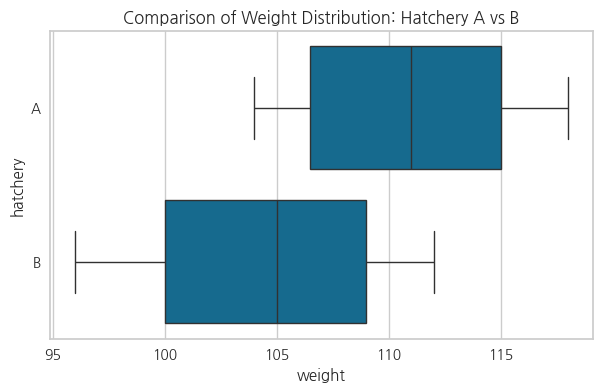

In [15]:
# matplotlib 라이브러리의 pyplot 사용
# seaborn 라이브러리 사용
# matplotlib.pyplot 라이브러리 함수

plt.figure(figsize=(7,4)) # 그래프 크기 설정
sns.boxplot(x = 'weight', y = 'hatchery', data= test)  # 박스플롯(Box Plot) 생성
plt.title('Comparison of Weight Distribution: Hatchery A vs B', fontsize = 12) # 그래프 제목 설정(부화장 A vs. B   무게 분포 비교)
plt.show() # 그래프 출력

#### t-test (귀무가설 : "두 집단의 평균은 같다")

In [6]:
# 부화장 A만 별도로 데이터셋 구성
test_a = test.loc[test.hatchery == 'A', 'weight']
test_a

,weight
0,112
1,116
2,106
3,104
4,116
5,118
6,110
7,112
8,106
9,108


| 코드              | 사용 라이브러리       | 설명                     |
| --------------- | -------------- | ---------------------- |
| test.loc[]    | pandas         | 데이터프레임에서 조건에 맞는 데이터 선택 |
| test.hatchery | pandas         | hatchery 컬럼 접근         |
| == 'A'        | 파이썬 기본 문법      | 부화장이 A인 데이터 조건 검색      |
| 'weight'      | pandas         | weight 컬럼만 선택          |
| dtype: int64  | pandas / numpy | 정수형(int) 데이터 타입 표시     |


In [7]:
# 부화장 B만 별도로 데이터셋 구성
test_b = test.loc[test.hatchery == 'B', 'weight']
test_b

# 부화장 A에 속한 병아리들의 몸무게만 추출한 결과

,weight
10,100
11,110
12,98
13,100
14,104
15,112
16,106
17,106
18,96
19,110


In [8]:
import scipy as sp # 통계·과학 계산 라이브러리

| 항목         | 설명                     |
| ---------- | ---------------------- |
| 라이브러리 이름   | SciPy                  |
| 역할         | 과학/통계/수학 계산            |
| 주 사용 분야    | 통계 분석, 확률, 최적화, 선형대수 등 |
| 보통 같이 쓰는 것 | numpy, pandas          |

##### scipy는 SciPy(사이파이)
#####  SciPy는 데이터 분석에서 통계 계산이 필요할 때 많이 사용
| 라이브러리          | 발음       | 주로 하는 일      |
| -------------- | -------- | ------------ |
| `NumPy`        | 넘파이      | 배열, 숫자 계산    |
| `Pandas`       | 판다스      | 데이터 분석·표 처리  |
| `SciPy`        | **사이파이** | 통계, 과학·수학 계산 |
| `scikit-learn` | **사이킷런** | 머신러닝         |
##### NumPy를 기반으로 SciPy가 과학·통계 계산 기능을 제공하고, scikit-learn은 머신러닝 기능을 제공한다

import scipy as sp   # 통계·과학 계산 라이브러리
| 기능       | 쉽게 말하면           |
| -------- | ---------------- |
| `t-test` | 두 그룹의 평균 차이 비교   |
| 상관관계     | 두 데이터가 관련 있는지 확인 |
| 확률분포     | 데이터의 확률 계산       |
| 통계 검정    | 결과가 우연인지 아닌지 판단  |
```
코드 예
from scipy import stats

# A부화장과 B부화장의 병아리 몸무게 평균에 차이가 있는지 검정
stats.ttest_ind(A_weight, B_weight)
```
SciPy(사이파이) : 데이터 분석에서 통계 검정, 확률, 과학·수학 계산 등에 사용하는 라이브러리

In [9]:
# 정규분포인지 확인하는 검사 (샤피로 검정)
# 부화장 A 샤피로 윌크 검정 실시 (귀무가설 : 정규분포를 이룬다),
# 기준: 0.05, p값 > 0.05  귀무가설 유지, p값 < 0.05  귀무가설 기각
sp.stats.shapiro(test_a)  # 샤피로-윌크 정규성 검정(데이터가 정규분포(종 모양)를 따르는지 검사)

# p값이 0.553으로 유의수준 0.05보다 크기 때문에 귀무가설 채택(정규분포 OK), 이 데이터 정상적인 분포 맞음, 이 데이터 써도 되는지 확인

ShapiroResult(statistic=np.float64(0.9400016973451231), pvalue=np.float64(0.5530322552073004))

| 코드          | 라이브러리        |
| ----------- | ------------ |
| sp        | scipy        |
| sp.stats  | scipy의 통계 기능 |
| shapiro() | 정규성 검정 함수    |


sp.stats.shapiro(test_a)
| 부분          | 설명                   |
| ----------- | -------------------- |
| test_a    | 부화장 A의 몸무게 데이터       |
| shapiro() | 정규분포인지 검사            |
| 결과          | statistic, pvalue 반환 |


# Shapiro-Wilk(샤피로-윌크) 정규성 검정 함수
| 부분          | 의미                 |
| ----------- | ------------------ |
| `sp`        | SciPy 라이브러리        |
| `stats`     | 통계 기능              |
| `shapiro()` | **정규분포인지 검사하는 함수** |
| `test_a`    | 검사할 데이터            |

##### p > 0.05 → 정규분포라고 보기 어려운 증거가 없음 → 보통 정규성 가정 가능
##### p ≤ 0.05 → 정규분포라고 보기 어려움
```
정규분포인지 확인하는 이유
뒤에서 t-test 같은 통계 검정을 하기 전에
데이터가 정규분포라는 조건을 만족하는지 확인하기 위해 사용하는 경우가 많다.

p-value = 0.32   → 32% → 정규분포로 봐도 됨
p-value = 0.08   →  8% → 정규분포로 봐도 됨
p-value = 0.03   →  3% → 정규분포라고 보기 어려움

Shapiro-Wilk 정규성 검정
p-value > 0.05 → 정규분포로 볼 수 있음
p-value ≤ 0.05 → 정규분포로 보기 어려움

```
| p-value     | 해석                  |
| ----------- | ------------------- |
| **0.05 초과** | 정규분포라고 **봐도 됨**    |
| **0.05 이하** | 정규분포라고 **보기 어려움**  |


In [10]:
sp.stats.shapiro(test_a) # Shapiro-Wilk 검정 : test_a 데이터가 정규분포(종 모양)를 따르는지 확인

ShapiroResult(statistic=np.float64(0.9400016973451231), pvalue=np.float64(0.5530322552073004))

| p-value | 의미            |
| ------- | ------------- |
| 0.05 이상 | 정규분포라고 볼 수 있음 |
| 0.05 미만 | 정규분포가 아님      |


| 코드                   | 의미             |
| -------------------- | -------------- |
| import scipy as sp | 통계/과학 계산 라이브러리 |
| sp.stats.shapiro() | 정규분포인지 검사      |
| pvalue > 0.05      | 정규분포라고 판단      |
| 현재 결과                | 정규분포에 가까움      |


| 결과        | 의미                  |
| --------- | ------------------- |
| statistic | 정규분포와 유사한 정도        |
| pvalue    | 정규분포라고 볼 수 있는 확률 기준 |


In [11]:
# 부화장 B 샤피로 윌크 검정 실시 (귀무가설 : 정규분포를 이룬다)
sp.stats.shapiro(test_b)

# → p값이 0.543으로 유의수준 0.05보다 크기 때문에 귀무가설 채택(정규분포 OK)

ShapiroResult(statistic=np.float64(0.9390683777600799), pvalue=np.float64(0.5426943326835627))

## t-test
- t-test는 **두 집단의 평균 차이가 우연히 나온 것인지** 통계적으로 확인하는 방법이다.
- 일반적으로 `p-value < 0.05`이면 '평균이 같다'라는 가정을 기각한다.
- `p-value > 0.05`라고 해서 '무조건 우연이다'라는 뜻은 아니다.
- 정확히는 **현재 데이터만으로는 두 집단의 차이가 통계적으로 뚜렷하다고 보기 어렵다**는 뜻이다.


In [12]:
# 두 집단의 평균 차이가 통계적으로 의미 있는지 검정
## t-test (귀무가설 : 두 집단의 평균은 같다), 귀무가설 기각 p값 = 0.0108, 기준 = 0.05 : 데이터 → 검증 (t-test)단계
sp.stats.ttest_ind(test_a, test_b)

TtestResult(statistic=np.float64(2.842528280230058), pvalue=np.float64(0.010803990633924204), df=np.float64(18.0))

In [13]:
# 두 집단의 평균 차이가 통계적으로 의미 있는지 검정
sp.stats.ttest_ind(test_a, test_b)

TtestResult(statistic=np.float64(2.842528280230058), pvalue=np.float64(0.010803990633924204), df=np.float64(18.0))

| p-value | 의미       |
| ------- | -------- |
| 0.05 이상 | 차이 없다고 봄 |
| 0.05 미만 | 차이 있다고 봄 |


| 개념         | 쉬운 의미         |
| ---------- | ------------- |
| 귀무가설       | 원래는 차이 없다고 가정 |
| T-Test     | 평균 차이 검사      |
| p-value    | 우연일 가능성       |
| p-value 작음 | 진짜 차이 같음      |
| 현재 결과      | A와 B 무게 차이 있음 |


통계 함수 장점
| 장점       | 설명         |
| -------- | ---------- |
| 객관적      | 숫자로 판단     |
| 기준 있음    | p-value 사용 |
| 대용량 가능   | 수만 개도 가능   |
| 논문/연구 가능 | 공식 검증 가능   |


### Shapiro와 t-test를 연결하면
##### Shapiro = 각각의 데이터가 정규분포로 볼 수 있는지 확인 (데이터모양 확인)
##### t-test =  두 그룹의 평균에 의미 있는 차이가 있는지 확인

```
A반 점수 → Shapiro ┐
                    ├→ 정규성 확인 → t-test → A반과 B반 평균 차이 확인
B반 점수 → Shapiro ┘
```
| 순서 | 검정             | 무엇을 확인?        | p-value 기준                  | 쉽게 말하면                |
| -- | -------------- | -------------- | --------------------------- | --------------------- |
| ①  | **Shapiro 검정** | 데이터가 정규분포인지 확인 | **p > 0.05** → 정규분포로 볼 수 있음 | 데이터 모양이 **종 모양인가?**   |
| ↓  |                | **정규성 확인 후**   |                             |                       |
| ②  | **t-test**     | 두 그룹의 평균 차이 확인 | **p < 0.05** → 평균 차이가 유의함   | 두 그룹의 평균이 **정말 다른가?** |


| 달걀 무게가 | 병아리 무게 |
| ------ | ------ |
| 가벼운 그룹 | 평균 38g |
| 무거운 그룹 | 평균 42g |
달걀 무게가 많이 나갈수록 병아리 무게도 많이 나가는가?”

라면 t-test보다는 상관관계 corr()가 더 직접적인 분석이다.

---
t-test는 질문이 다릅니다.

“A 부화장 병아리와 B 부화장 병아리의 평균 무게가 다른가?” → t-test
| 내가 궁금한 것                     | 사용                |
| ---------------------------- | ----------------- |
| 달걀이 무거울수록 병아리도 무거운가?         | **상관분석 `corr()`** |
| A부화장과 B부화장의 평균 무게가 다른가?      | **t-test**        |
| t-test를 적용하기 적절한 정규성 조건인지 확인 | **Shapiro**       |
결국 통계검정은 “눈으로 봐서 그런 것 같다”를 “숫자로 근거를 대서 그렇다고 판단”하기 위해 하는 겁니다.

# 🐥 병아리 부화장 A/B 몸무게 비교 분석

## 1. 데이터 불러오기

```python
# 데이터 분석에 필요한 공통 라이브러리와 설정 불러오기
%run start.py

# 병아리 데이터 읽기
test = pd.read_csv('data/chick003.csv')

# 데이터 구조 확인
test.info()

# 전체 데이터 확인
print(test)
```

이 데이터는 부화장별 병아리 몸무게를 기록한 데이터이다.

| 컬럼         | 의미      |
| ---------- | ------- |
| `hatchery` | 부화장     |
| `chick_nm` | 병아리 번호  |
| `weight`   | 병아리 몸무게 |

---

## 2. 부화장별 몸무게 분포 확인

```python
# 부화장 A와 B의 몸무게 분포를 박스플롯으로 비교
plt.figure(figsize=(7, 4))

sns.boxplot(
    x='weight',
    y='hatchery',
    data=test
)

plt.title(
    'Comparison of Weight Distribution: Hatchery A vs B',
    fontsize=12
)

plt.show()
```

그래프를 통해 부화장 A와 B의 병아리 몸무게 분포에 차이가 있는지 먼저 눈으로 확인한다.

하지만 그래프만 보고 실제 차이가 있다고 판단할 수는 없다.

---

## 3. 부화장 A와 B 데이터 분리

```python
# 부화장 A 병아리의 몸무게만 추출
test_a = test.loc[
    test.hatchery == 'A',
    'weight'
]

test_a
```

```python
# 부화장 B 병아리의 몸무게만 추출
test_b = test.loc[
    test.hatchery == 'B',
    'weight'
]

test_b
```

이제 A와 B 두 그룹의 몸무게 데이터를 따로 준비하였다.

---

## 4. SciPy 불러오기

```python
# 통계·과학 계산을 위한 SciPy 라이브러리
import scipy as sp
```

`SciPy`는 통계 검정, 확률, 수학 계산 등에 사용하는 라이브러리이다.

---

# 5. Shapiro-Wilk 정규성 검정

t-test를 하기 전에 두 그룹의 데이터가 정규분포로 볼 수 있는지 확인한다.

```python
# 부화장 A 데이터가 정규분포를 따르는지 확인
sp.stats.shapiro(test_a)
```

결과에서 `p-value`를 확인한다.

```text
A 부화장 p-value ≈ 0.553
```

```python
# 부화장 B 데이터가 정규분포를 따르는지 확인
sp.stats.shapiro(test_b)
```

```text
B 부화장 p-value ≈ 0.543
```

판단 기준은 다음과 같다.

| p-value    | 판단            |
| ---------- | ------------- |
| `p > 0.05` | 정규분포로 볼 수 있음  |
| `p ≤ 0.05` | 정규분포라고 보기 어려움 |

A와 B 모두 `0.05`보다 크므로 정규분포로 볼 수 있다.

따라서 t-test를 진행할 수 있다.

---

# 6. 독립표본 t-test

이제 A 부화장과 B 부화장 병아리의 평균 몸무게가 실제로 차이가 있는지 확인한다.

```python
# 두 그룹의 평균 차이가 통계적으로 의미 있는지 검정
sp.stats.ttest_ind(test_a, test_b)
```

결과:

```text
TtestResult(
    statistic=2.8425,
    pvalue=0.0108,
    df=18
)
```

여기서는 `p-value`를 중심으로 본다.

```text
p-value = 0.0108
```

판단 기준:

| p-value    | 판단                  |
| ---------- | ------------------- |
| `p < 0.05` | 두 그룹의 평균 차이가 유의함    |
| `p ≥ 0.05` | 평균 차이가 유의하다고 보기 어려움 |

현재 결과는

```text
0.0108 < 0.05
```

이므로,

> **부화장 A와 B 병아리의 평균 몸무게에는 통계적으로 유의한 차이가 있다고 판단한다.**

---

# 📊 분석 보고서

## 1. 분석 목적

부화장 A와 B에서 태어난 병아리의 몸무게를 비교하여, 두 부화장의 병아리 평균 몸무게에 실제로 의미 있는 차이가 있는지 확인하였다.

---

## 2. 분석 방법

먼저 각 부화장의 몸무게 데이터를 분리하였다.

그다음 Shapiro-Wilk 검정을 이용하여 데이터가 정규분포를 따르는지 확인하였다.

A와 B 모두 `p-value`가 0.05보다 크게 나타나 정규분포로 볼 수 있었다.

이후 독립표본 t-test를 이용하여 두 부화장의 평균 몸무게 차이를 검정하였다.

---

## 3. 분석 결과

t-test 결과 `p-value`는 약 **0.0108**로 나타났다.

이는 기준값인 **0.05보다 작은 값**이다.

따라서 두 부화장의 평균 몸무게가 같다고 보는 가정을 기각하고, 부화장 A와 B의 병아리 평균 몸무게에는 통계적으로 유의한 차이가 있다고 판단할 수 있다.

---

## 4. 결론

> **부화장 A와 B 병아리의 몸무게 차이는 단순히 눈으로 보이는 차이가 아니라, 통계적으로도 의미 있는 차이라고 판단할 수 있다.**

즉, 통계 검정을 하는 이유는

> **“그냥 달라 보인다”를 “숫자로 확인했더니 실제로 차이가 있다고 볼 수 있다”로 바꾸기 위해서이다.**

---

# ⭐ 핵심 정리

| 분석        | 목적                    |
| --------- | --------------------- |
| `Shapiro` | 데이터가 정규분포로 볼 수 있는지 확인 |
| `t-test`  | 두 그룹의 평균이 실제로 다른지 확인  |
| `p-value` | 통계적으로 판단하기 위한 기준      |
| `0.05`    | 일반적으로 많이 사용하는 유의수준 기준 |

### 최종 흐름

```text
병아리 데이터
      ↓
A / B 그룹 분리
      ↓
Shapiro 검정
      ↓
정규성 확인
      ↓
t-test
      ↓
A와 B 평균 차이가 실제로 의미 있는지 판단
```

### 상관분석과의 차이

| 질문                       | 사용        |
| ------------------------ | --------- |
| 달걀이 무거울수록 병아리도 무거운가?     | `corr()`  |
| A부화장과 B부화장의 평균 무게가 다른가?  | `t-test`  |
| t-test 전에 정규성을 확인하고 싶은가? | `Shapiro` |


# 📊 분석 보고서

## 1. 분석 목적
부화장 A와 B에서 태어난 병아리의 몸무게를 비교하여 두 부화장의 **평균 몸무게에 통계적으로 의미 있는 차이가 있는지** 확인하였다.

## 2. 분석 방법
먼저 A와 B 부화장의 몸무게 데이터를 각각 분리하였다. 이후 Shapiro-Wilk 검정을 이용하여 두 그룹의 정규성을 확인하고, 독립표본 t-test를 이용하여 평균 몸무게 차이를 검정하였다.

## 3. Shapiro 검정 결과
A와 B 그룹의 Shapiro 검정 결과에서 p-value가 모두 0.05보다 크다면 두 그룹을 정규분포로 볼 수 있다. 따라서 t-test를 이용하여 두 그룹의 평균을 비교할 수 있다.

## 4. t-test 결과
t-test의 p-value가 0.05보다 작으면 **A와 B 부화장의 평균 몸무게에는 통계적으로 유의한 차이가 있다**고 판단한다.

## 5. 결론
통계 검정은 단순히 그래프나 평균값을 보고 '달라 보인다'고 판단하는 것이 아니라, **그 차이가 통계적으로 의미가 있는지를 숫자로 확인하는 과정**이다.

> **Shapiro = t-test를 적용하기 위한 정규성 확인 → t-test = 두 그룹 평균의 차이가 의미 있는지 확인**


```
Shapiro
"정규분포로 볼 수 있나?"
        ↓
   p > 0.05
        ↓
t-test
"A와 B의 평균이 같은가?"
        ↓
   p < 0.05
        ↓
"평균 차이가 통계적으로 유의하다"
```
```
Shapiro = 정규분포인지 확인(정규분포라면 나와야할값들과 실제데이터가 비슷한지)
t-test = 두 그룹의 평균 차이가 통계적으로 의미 있는지 확인 (평균과 분산도같이봄, 데이터의 퍼짐정도)
p-value = 그 결과를 판단하기 위한 값(보통 0.05 기준)
```

| 방법          | 내부에서 하는 일                          | 결과           |
| ----------- | ---------------------------------- | ------------ |
| **Shapiro** | 실제 데이터의 분포가 정규분포와 얼마나 잘 맞는지 계산     | p-value      |
| **t-test**  | **평균 차이 + 데이터의 흩어짐**을 이용해 t값 계산    | t값 → p-value |
| **p-value** | 가정이 맞을 때 **지금 같은 결과가 얼마나 드문지** 나타냄 | 보통 0.05와 비교  |
```
Shapiro는 데이터의 모양을 수학적으로 검사하고,
t-test는 평균 차이가 데이터의 흔들림에 비해 충분히 큰지를 수학적으로 검사한다. p-value는 그 결과가 얼마나 드문지를 판단하는 값이다.

특히 t-test = 단순히 평균 두 개만 비교하는 게 아니다가 핵심이다.
평균의 차이와 데이터의 퍼진 정도(분산)를 함께 본다.
